
--- Initiating Spatial Clustering for PUNE ---
  -> Loading and merging drainage networks...
  -> Extracting topographical features...
  -> Calculating drainage proximity matrix...
  -> Executing K-Means Clustering...
  -> Success! Spatial zones mapped and saved to d:\B\PA\projectv1.0\Urban_Flood_EWS\models\pune_vulnerability_zones.geojson
  -> Generating visual map...


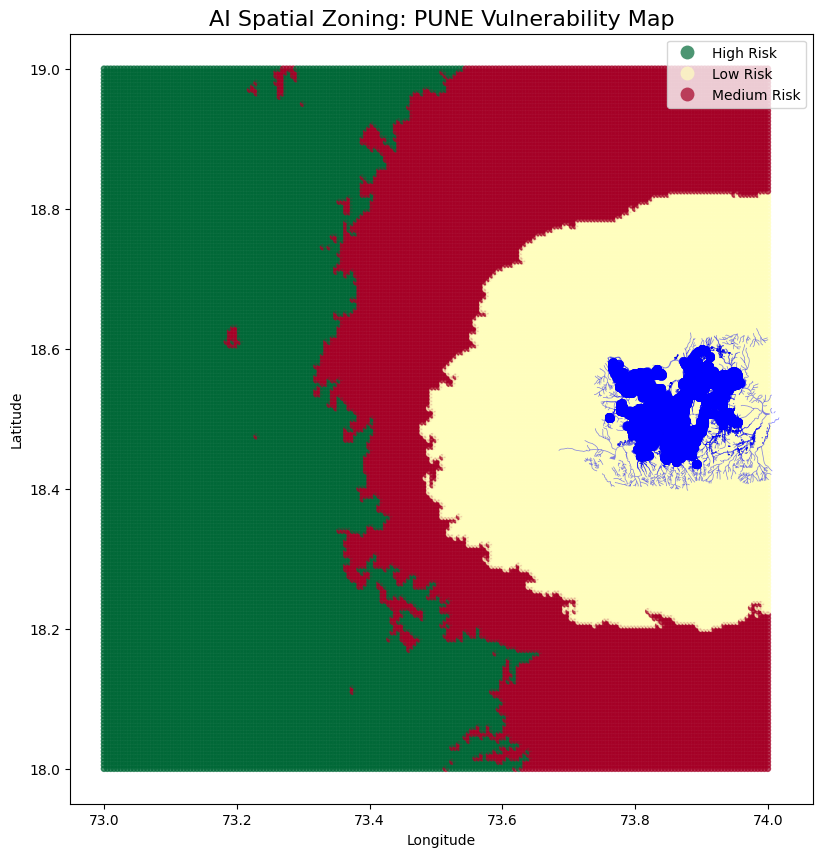


--- Initiating Spatial Clustering for MUMBAI ---
  -> Loading and merging drainage networks...
  -> Extracting topographical features...
  -> Calculating drainage proximity matrix...
  -> Executing K-Means Clustering...
  -> Success! Spatial zones mapped and saved to d:\B\PA\projectv1.0\Urban_Flood_EWS\models\mumbai_vulnerability_zones.geojson
  -> Generating visual map...


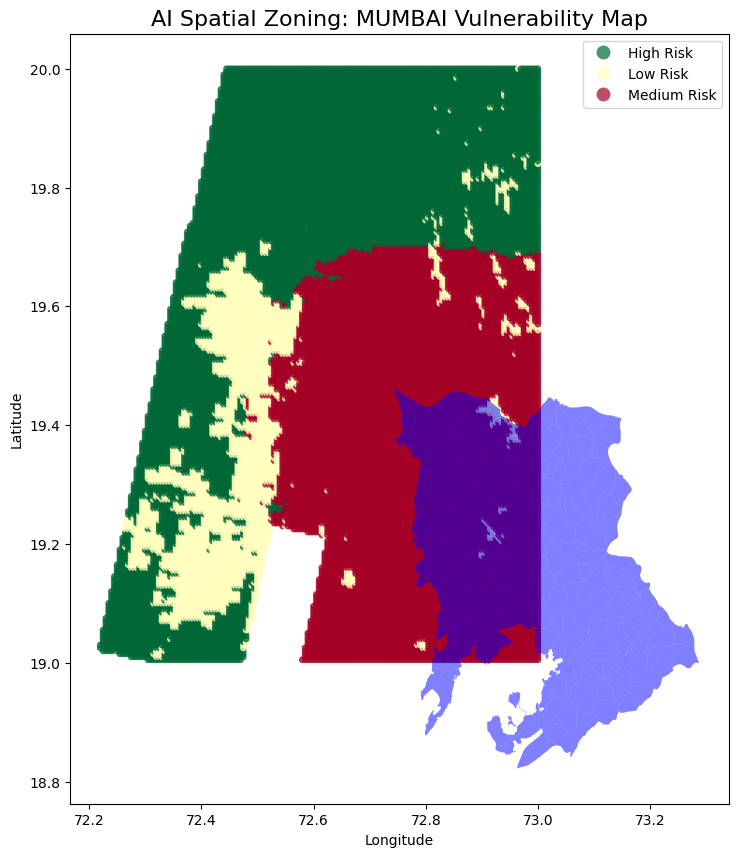


--- Initiating Spatial Clustering for BENGALURU ---
  -> Loading and merging drainage networks...
  -> Extracting topographical features...
  -> Calculating drainage proximity matrix...
  -> Executing K-Means Clustering...
  -> Success! Spatial zones mapped and saved to d:\B\PA\projectv1.0\Urban_Flood_EWS\models\bengaluru_vulnerability_zones.geojson
  -> Generating visual map...


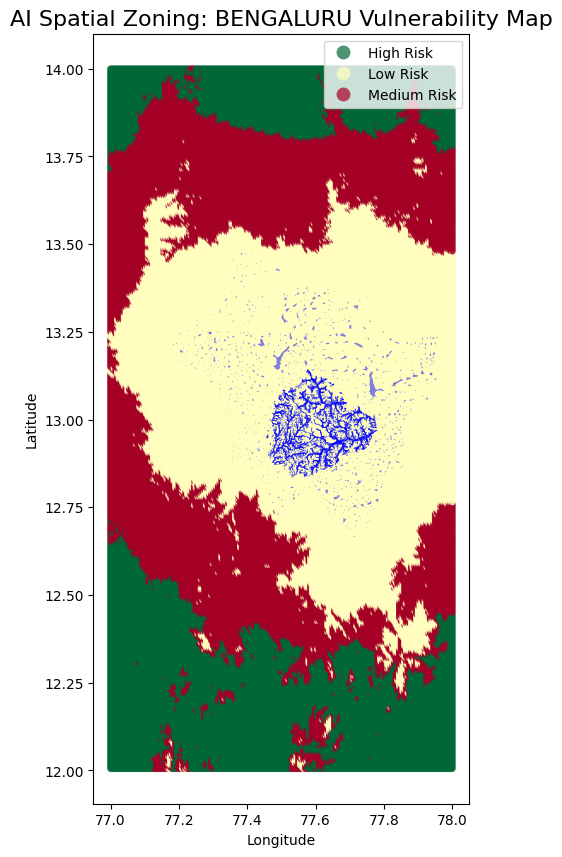


--- Initiating Spatial Clustering for CHENNAI ---
  -> Loading and merging drainage networks...


C:\Users\uberm\AppData\Local\Temp\ipykernel_30272\4146424493.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  city_drains = gpd.GeoDataFrame(pd.concat(drain_gdfs, ignore_index=True), crs="EPSG:4326")


  -> Extracting topographical features...
  -> Calculating drainage proximity matrix...
  -> Executing K-Means Clustering...
  -> Success! Spatial zones mapped and saved to d:\B\PA\projectv1.0\Urban_Flood_EWS\models\chennai_vulnerability_zones.geojson
  -> Generating visual map...


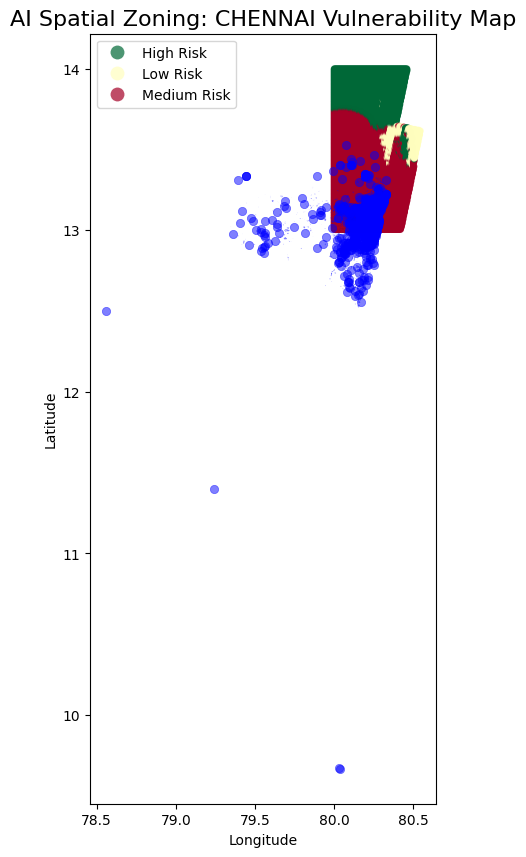


Pipeline Step 5a Complete: Topographical Clustering and Zoning Finished!


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import Point
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Handle paths safely for Jupyter Notebooks
# Jupyter usually sets the working dir to where the notebook is, so we navigate relative to that
current_dir = os.getcwd()
if "scripts" in current_dir:
    project_root = os.path.dirname(current_dir)
else:
    project_root = current_dir

processed_dir = os.path.join(project_root, "data", "processed")
models_dir = os.path.join(project_root, "models")
os.makedirs(models_dir, exist_ok=True)

cities = ["pune", "mumbai", "bengaluru", "chennai"]

def create_vulnerability_zones(city):
    print(f"\n--- Initiating Spatial Clustering for {city.upper()} ---")
    city_dir = os.path.join(processed_dir, city)
    
    # 1. Locate the stitched DEM (Elevation) and the standardized Drains
    dem_files = glob.glob(os.path.join(city_dir, "*_seamless_dem.tif"))
    drain_files = glob.glob(os.path.join(city_dir, "*_standardized.geojson"))
    
    if not dem_files or not drain_files:
        print(f"  -> Missing required Pillar I or II data for {city}. Skipping.")
        return

    dem_path = dem_files[0]
    
    # Merge all drainage files into one massive network for the city
    print("  -> Loading and merging drainage networks...")
    drain_gdfs = [gpd.read_file(f) for f in drain_files]
    city_drains = gpd.GeoDataFrame(pd.concat(drain_gdfs, ignore_index=True), crs="EPSG:4326")
    
    # 2. Open the Elevation Map and create a sampling grid
    print("  -> Extracting topographical features...")
    with rasterio.open(dem_path) as src:
        bounds = src.bounds
        # Create a grid of points (e.g., every 0.005 degrees, roughly 500 meters)
        x_coords = np.arange(bounds.left, bounds.right, 0.005)
        y_coords = np.arange(bounds.bottom, bounds.top, 0.005)
        
        grid_points = [Point(x, y) for x in x_coords for y in y_coords]
        grid_gdf = gpd.GeoDataFrame(geometry=grid_points, crs="EPSG:4326")
        
        # Sample elevation for each point
        elevations = []
        for point in grid_points:
            try:
                # Sample returns a generator, we extract the first value
                val = list(src.sample([(point.x, point.y)]))[0][0]
                elevations.append(val)
            except Exception:
                elevations.append(np.nan)
            
        grid_gdf['elevation'] = elevations

    # 3. Calculate spatial relationship (Distance to nearest drain)
    print("  -> Calculating drainage proximity matrix...")
    # Convert to a projected CRS (meters) for accurate distance calculation
    grid_gdf_proj = grid_gdf.to_crs("EPSG:3857")
    city_drains_proj = city_drains.to_crs("EPSG:3857")
    
    # Use spatial index for fast nearest-neighbor calculation
    distances = grid_gdf_proj.geometry.apply(lambda geom: city_drains_proj.distance(geom).min())
    grid_gdf['drain_distance_m'] = distances

    # 4. Clean the data (remove NoData values and NaNs)
    grid_gdf = grid_gdf.dropna(subset=['elevation'])
    grid_gdf = grid_gdf[grid_gdf['elevation'] > -500] 
    
    # 5. K-Means Clustering Machine Learning
    print("  -> Executing K-Means Clustering...")
    # Invert elevation so high numbers mean "lower ground" for the algorithm
    grid_gdf['inv_elevation'] = grid_gdf['elevation'].max() - grid_gdf['elevation']
    
    features = grid_gdf[['inv_elevation', 'drain_distance_m']].values
    
    # Standardize the features so distance and elevation are weighed equally
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(features)
    
    # Cluster into 3 Zones (0, 1, 2)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    grid_gdf['cluster'] = kmeans.fit_predict(scaled_features)
    
    # 6. Map the clusters to human-readable Risk Zones
    cluster_centers = kmeans.cluster_centers_
    risk_scores = cluster_centers.sum(axis=1) 
    
    # Sort clusters by risk score
    sorted_clusters = np.argsort(risk_scores)
    risk_mapping = {
        sorted_clusters[0]: "Low Risk",
        sorted_clusters[1]: "Medium Risk",
        sorted_clusters[2]: "High Risk"
    }
    
    grid_gdf['risk_zone'] = grid_gdf['cluster'].map(risk_mapping)
    
    # 7. Export the Spatial Model Output
    output_path = os.path.join(models_dir, f"{city}_vulnerability_zones.geojson")
    
    # Drop the temporary calculation columns
    final_output = grid_gdf[['geometry', 'elevation', 'drain_distance_m', 'risk_zone']]
    final_output.to_file(output_path, driver="GeoJSON")
    
    print(f"  -> Success! Spatial zones mapped and saved to {output_path}")

    # 8. Visualizing the Results (MOVED INSIDE THE FUNCTION)
    print("  -> Generating visual map...")
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Plot Risk Zones
    grid_gdf.plot(column='risk_zone', 
                  cmap='RdYlGn_r', 
                  legend=True, 
                  ax=ax, 
                  markersize=15, 
                  alpha=0.7)
    
    # Overlay drainage pipes
    city_drains.plot(ax=ax, color='blue', linewidth=0.5, alpha=0.5)
    
    plt.title(f"AI Spatial Zoning: {city.upper()} Vulnerability Map", fontsize=16)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.show()

# Execute the clustering
for city in cities:
    create_vulnerability_zones(city)

print("\nPipeline Step 5a Complete: Topographical Clustering and Zoning Finished!")